In [1]:
import os
import numpy as np
import cv2 as cv
from skimage.io import imread
import matplotlib.pyplot as plt

# libraries to test
import sys
sys.path.append("../")
from frangi_2dfilter import frangi_2Dfilter
from fuzzy_thresholding import fuzzy_thresholding
from adaptive_thresholding import adaptive_thresholding

# Testing
We will be testing the Frangi 2D and Adaptive thresholding translations to ensure they work properly for skeletonization

# Utilities

In [2]:
def BinarizeImage(Im:np.ndarray, frangi_sigma = 8, frangi_enabled = True, method = "Fuzzy Means") -> np.ndarray:
    """
    Binarizes an image using the selected method and options from the GUI app.

    Parameters:
    - app: GUI application object containing UI state (e.g., checkboxes, dropdowns)
    - Im: Input image as a 2D NumPy array (grayscale)

    Returns:
    - Binarized image as a 2D NumPy array (dtype=float)
    """
    # Find the brightest pixel in the image
    col_max_vals = np.max(Im, axis=0) # the maximum of each column
    cc = np.argmax(col_max_vals) #  gets the index of the column where the brightest value occurred
    rr = np.argmax(Im[:, cc]) # captures the row index of that max value

    #	•	rr: row of the brightest pixel
	#   •	cc: column of the brightest pixel
    #   •	So (rr, cc) is the coordinate of the brightest pixel in the whole image.

    # Apply Frangi filter if selected
    if frangi_enabled:
        opts = {
            'sigmarange': [1, frangi_sigma],
            'sigmastepsize': 2,
            'correctionconst1': 0.8,
            'correctionconst2': 15
        }
        Im = frangi_2Dfilter(Im, opts)

    # Apply the selected binarization method
    if method == 'Fuzzy Means':
        nth = 2
        Im = fuzzy_thresholding(Im, nth, 3) - 1

    elif method == 'Adaptive Thresholding':
        Im = adaptive_thresholding(Im, 70).astype(float)

    else:
        raise ValueError("Incorrect Segmentation Method")

    # Ensure vessels are white, background is black, turning the image into black and white
    vessel_value = Im[rr, cc]
    Im[Im == vessel_value] = 255
    Im[Im != 255] = 0

    return Im

def overlay_mask(img, mask, color=(1, 0, 0), alpha=0.5):
    """
    Overlay a binary mask on a grayscale image.

    Parameters:
    - img: grayscale image (H,W)
    - mask: binary mask (H,W), values 0 or 255
    - color: tuple with RGB values (0-1 range for matplotlib)
    - alpha: transparency of overlay

    Returns:
    - RGB image with overlay
    """
    # Normalize grayscale for display
    img_norm = cv.normalize(img, None, 0, 1, cv.NORM_MINMAX)

    # Convert grayscale to RGB
    img_rgb = np.stack([img_norm]*3, axis=-1)

    # Create color mask
    mask_bool = mask > 0
    overlay = np.zeros_like(img_rgb)
    overlay[mask_bool] = color

    # Blend images
    blended = (1 - alpha) * img_rgb + alpha * overlay
    return blended


def center_crop(img, dim):
    """
    Center crop an image (2D NumPy array).

    Parameters:
        img (np.ndarray): Input image (H x W).
        dim (tuple): Desired output size (h, w).

    Returns:
        np.ndarray: Cropped image of size (h, w).
    """
    h, w = img.shape[:2]
    new_h, new_w = dim

    if new_h > h or new_w > w:
        raise ValueError("Crop size must be smaller than the image size")

    top = (h - new_h) // 2
    left = (w - new_w) // 2

    return img[top: top + new_h, left: left + new_w]

In [3]:
pwd

'/home/mutrera/OCTAVA/octava/code'

In [12]:
octa_path = "/home/mutrera/OCTAVA/octava/code/10306.bmp"
img = imread(octa_path, as_gray=True)
img = img.astype(np.float32)

# Find the brightest pixel in the image
col_max_vals = np.max(img, axis=0) # the maximum of each column
cc = np.argmax(col_max_vals) #  gets the index of the column where the brightest value occurred
rr = np.argmax(img[:, cc]) # captures the row index of that max value

opts = {
            'sigmarange': [1, 8],
            'sigmastepsize': 2,
            'correctionconst1': 0.8,
            'correctionconst2': 15
        }

frangid = frangi_2Dfilter(img, opts)

# vessel_value = frangid[rr, cc]
# frangid[frangid == vessel_value] = 255
# frangid[frangid != 255] = 0

fuzzyd = BinarizeImage(img, frangi_sigma=8, frangi_enabled=True)
adpt = BinarizeImage(img, frangi_sigma=8, frangi_enabled=True, method="Adaptive Thresholding")

fuzzy_overlay = overlay_mask(img, fuzzyd, color=(255, 255, 0), alpha = 0.4)
adaptive_overlay = overlay_mask(img, adpt, color=(255, 255, 0), alpha = 0.4)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..102.6].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..102.6].


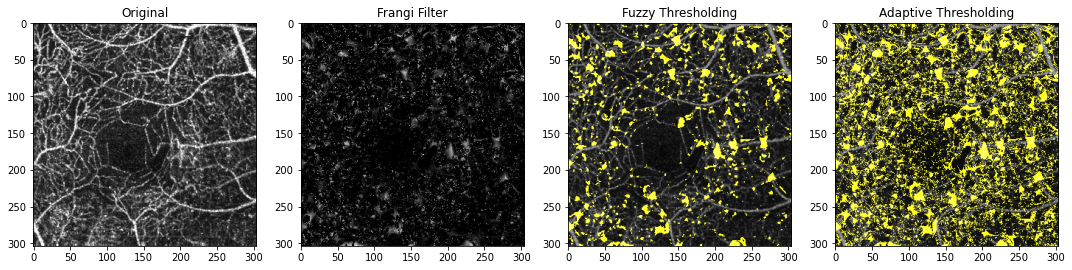

In [13]:
fig, ax = plt.subplots(1, 4, figsize=(15, 15))

ax[0].imshow(img, cmap = 'gray')
ax[0].set_title("Original")

ax[1].imshow(frangid, cmap = 'gray')
ax[1].set_title("Frangi Filter")

ax[2].imshow(fuzzy_overlay, cmap = 'gray')
ax[2].set_title("Fuzzy Thresholding")

ax[3].imshow(adaptive_overlay, cmap = 'gray')
ax[3].set_title("Adaptive Thresholding")

plt.tight_layout()
plt.show()

# Conclusions

**Frangi:** Needs images to be float type, so must convert them by doing imb.astype(np.float32) or smth of the sort

**Fuzzy Thresholding:** Had issues with divisions by zero which I solved by adding an epsilon value. Not sure if output is correct based on the above results

**Adaptive Thresholding:** There is output and matches the pixel values from MATLAB, but not sure the output is correct based on the above results

# Experimentation with Built-in Libraries
I think the previous segmentations are wrong due to a wrong application of the Frangi filtering. So I will use the built-in version provided by skimage

In [7]:
import skfuzzy as fuzz
from skimage.filters import frangi

In [8]:
# frangi filtering first 
from matplotlib import colors

cmap_yellow = colors.ListedColormap(['black', 'yellow'])
vessels = frangi(
    img,
    scale_range=(0.5, 4),
    scale_step=0.5,
    alpha=0.5,
    beta=0.5,
    gamma=4,
    black_ridges=False
)

fuzzy_mask = BinarizeImage(vessels, 8, False)
fuzzy_mask_overlay = overlay_mask(img, fuzzy_mask, color = (255, 255, 0), alpha = 0.4)

/tmp/ipykernel_46884/3161759798.py:5: UserWarning: Use keyword parameter `sigmas` instead of `scale_range` and `scale_range` which will be removed in version 0.17.
  vessels = frangi(


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..102.6].


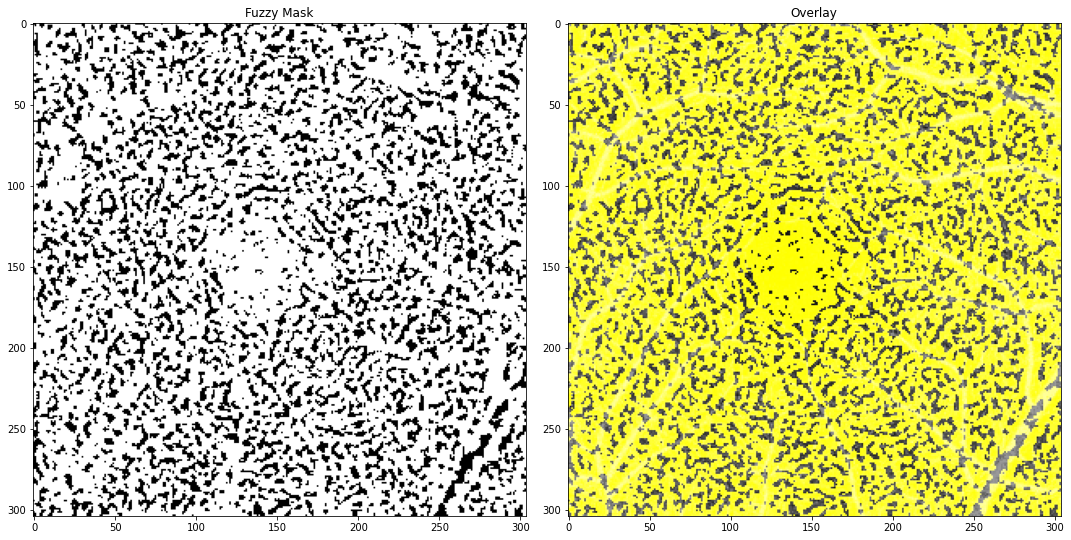

In [9]:
fig, ax = plt.subplots(1, 2, figsize = (15, 15))

ax[0].imshow(fuzzy_mask, cmap='gray')
ax[0].set_title("Fuzzy Mask")

ax[1].imshow(fuzzy_mask_overlay, cmap='gray')
ax[1].set_title("Overlay")

plt.tight_layout()
plt.show()

In [10]:
adpt_mask = BinarizeImage(vessels, 8, False, method = "Adaptive Thresholding")
adpt_mask_overlay = overlay_mask(vessels, adpt_mask, color = (255, 255, 0), alpha = 0.4)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..102.6].


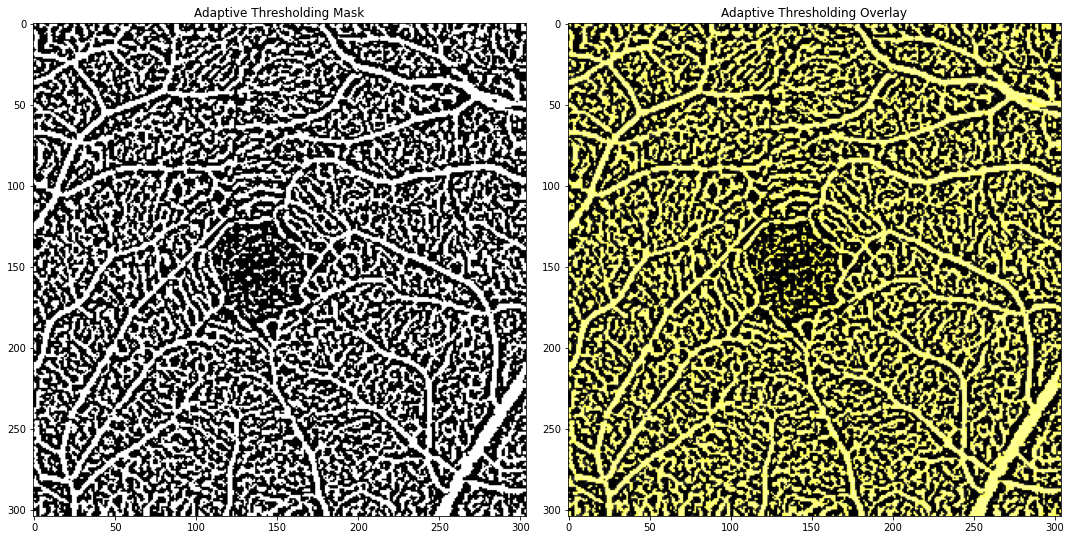

In [11]:
fig, ax = plt.subplots(1, 2, figsize = (15, 15))

ax[0].imshow(adpt_mask, cmap='gray')
ax[0].set_title("Adaptive Thresholding Mask")

ax[1].imshow(adpt_mask_overlay, cmap='gray')
ax[1].set_title("Adaptive Thresholding Overlay")

plt.tight_layout()
plt.show()